# Neural Network (MLP) — Credit Default Prediction and Explanations

**Methodology (matches the group deck):**

* **Data:** PyCaret's 24,000-row copy of the UCI Default of Credit Card Clients data (the file the rest of the group uses).
* **Features:** `SEX` and `MARRIAGE` are excluded from the model, as in the group's models.
* **Split:** 75/25 stratified train/test split. Decline if P(default) ≥ 50%.
* **LIME:** 5,000 samples, default kernel, re-run with 20 seeds; reasons compared as the **top 4** (adverse-action notices list up to four).
* **Counterfactuals:** only the latest lateness, the latest balance and the last two payments can change, each in its allowed direction.

`RANDOM_STATE = 42` sets the split. If the group used a different seed, change it so the test sets match.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

In [38]:
import os
import urllib.request

# Same data as the rest of the group: PyCaret's 24,000-row copy of the UCI file.
# If ../data/credit.csv isn't there yet, download it from PyCaret's dataset repository.
DATA_PATH = os.path.join("..", "data", "credit.csv")
PYCARET_URLS = [
    "https://raw.githubusercontent.com/pycaret/datasets/main/data/common/credit.csv",
    "https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/credit.csv",
]

if not os.path.exists(DATA_PATH):
    for url in PYCARET_URLS:
        try:
            urllib.request.urlretrieve(url, DATA_PATH)
            print("Downloaded", url)
            break
        except Exception as err:
            print("Could not download", url, "->", err)
    else:
        raise FileNotFoundError(
            "Put the group's 24,000-row credit.csv in the data folder (or install pycaret and run "
            "pycaret.datasets.get_data('credit').to_csv(DATA_PATH, index=False))."
        )

df = pd.read_csv(DATA_PATH)

# PyCaret calls the latest month PAY_1 and the target 'default'; use the UCI names this notebook expects
df = df.rename(columns={"PAY_1": "PAY_0", "default": "DEFAULT", "default payment next month": "DEFAULT"})
assert {"PAY_0", "DEFAULT"} <= set(df.columns), df.columns.tolist()

df.head()

Downloaded https://raw.githubusercontent.com/pycaret/datasets/main/data/common/credit.csv


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,90000,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
2,50000,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
3,50000,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
4,50000,1,1,2,37,0,0,0,0,0,0,64400.0,57069.0,57608.0,19394.0,19619.0,20024.0,2500.0,1815.0,657.0,1000.0,1000.0,800.0,0


In [39]:
df.shape  # expect (24000, 24): 23 predictors + target (PyCaret's copy has no ID column)

(24000, 24)

In [40]:
df.columns.tolist() # names of the predictors

['LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'DEFAULT']

In [41]:
# We simplify the target: from default payment next month to DEFAULT
df = df.rename(
    columns={"default payment next month": "DEFAULT"}
)

In [42]:
df["DEFAULT"].value_counts() # Counts number of observations of each class of the target (0: no default, 1: default)

DEFAULT
0    18694
1     5306
Name: count, dtype: int64

In [43]:
df["DEFAULT"].value_counts(normalize=True) # The same, but it returns proportions instead of absolute magnitudes

DEFAULT
0    0.778917
1    0.221083
Name: proportion, dtype: float64

In [44]:
# ID (if present) is just an identifier. SEX and MARRIAGE are protected attributes and are
# excluded, exactly as in the group's logistic regression and XGBoost models.
X = df.drop(columns=["ID", "DEFAULT", "SEX", "MARRIAGE"], errors="ignore")
y = df["DEFAULT"]

In [45]:
# Train / test split. IMPORTANT: The rest of the models, like Logistic Regression and XGBoost have to use the same one
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,  # 75/25, as in the group's models
    stratify=y,  # Keeps approximately the same percentage of defaults in Train and Test
    random_state=RANDOM_STATE
)

In [46]:
# It should be Train: 18,000 and Test: 6,000
print(X_train.shape)
print(X_test.shape)

print(y_train.mean())
print(y_test.mean())

(18000, 21)
(6000, 21)
0.22111111111111112
0.221


In [47]:
# PREPROCESSING
# Very important because each predictor has a different scale, and neuronal netowrks (NN) are sensible to scale. 
# E.g. AGE ≈ 20–80, LIMIT_BAL ≈ Tens/hundreds of thousands, BILL_AMT1 ≈ Tens/hundreds of thousands, PAY_AMT1 ≈ thousands
# We must standarize

# ==============================================================================
# 1. FEATURE PARTITIONING
# ==============================================================================
# Explicitly identify nominal categorical variables.
# EDUCATION uses numeric codes (1 = graduate school, 2 = university, 3 = high school, ...).
# We treat them as distinct categories, not ordinal numbers with mathematical order.
# (SEX and MARRIAGE were dropped above, as in the group's models.)
categorical_features = [
    "EDUCATION",
]

# Every column that isn't categorical is treated as numeric (e.g., LIMIT_BAL, AGE,
# payment histories PAY_0-PAY_6, and bill/payment amounts BILL_AMT*, PAY_AMT*).
numeric_features = [
    col for col in X.columns 
    if col not in categorical_features
]


# ==============================================================================
# 2. DEFINING THE PREPROCESSING PIPELINE
# ==============================================================================
# ColumnTransformer applies specific transformations to specific subsets of columns
# and stitches the resulting arrays back together into a single feature matrix.
preprocessor = ColumnTransformer(
    transformers=[
        # Pipeline 1: Scale numeric variables
        # Centers data at mean 0 with standard deviation 1.
        # Essential for Logistic Regression and Neural Networks so that large values
        # (like LIMIT_BAL = 500,000) don't dominate small values (like PAY_0 = 2).
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        
        # Pipeline 2: Convert categories to one-hot binary flags (0 or 1)
        # - handle_unknown="ignore": Prevents code crashes if an unseen category appears in test data.
        # - sparse_output=False: Produces a dense NumPy array (required by SHAP and LIME).
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
    ],
    # verbose_feature_names_out=False keeps output names clean 
    # (e.g., "EDUCATION_1" instead of "categorical__EDUCATION_1").
    verbose_feature_names_out=False
)


# ==============================================================================
# 3. FITTING AND TRANSFORMING (PREVENTING DATA LEAKAGE)
# ==============================================================================
# Step A: fit_transform() on the TRAINING data ONLY.
# - 'fit': Learns the mean/std dev and unique categories from X_train.
# - 'transform': Converts X_train using those learned parameters.
X_train_processed = preprocessor.fit_transform(X_train)

# Step B: transform() on the TEST data.
# Uses the training parameters (mean/std) to scale the test data.
# NEVER call fit() on test data; doing so leaks test distribution into the training pipeline.
X_test_processed = preprocessor.transform(X_test)

# We check the result
feature_names = preprocessor.get_feature_names_out()

feature_names

array(['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
       'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
       'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
       'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'EDUCATION_0', 'EDUCATION_1',
       'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'EDUCATION_5',
       'EDUCATION_6'], dtype=object)

This configuration specifies a feedforward Multilayer Perceptron (MLP) for binary classification on the preprocessed tabular credit dataset (20 numeric features plus one-hot education codes).

---

#### 1. Network Architecture
* **`hidden_layer_sizes=(64, 32)`**: The first hidden layer projects the preprocessed features into a 64-dimensional latent space to model feature interactions; the second layer compresses this representation to 32 dimensions prior to the binary output node.
* **`activation="relu"`**: Rectified Linear Unit ($f(x) = \max(0, x)$). Introduces non-linearity across hidden units while mitigating vanishing gradients during backpropagation.

---

#### 2. Optimization
* **`solver="adam"`**: Adaptive Moment Estimation. Dynamically updates weights using exponentially decaying running averages of past gradients and squared gradients.
* **`learning_rate_init=0.001`**: Initial step size for the Adam optimizer.
* **`batch_size=256`**: Mini-batch size per gradient update. Balances vectorized computation throughput against stochastic gradient noise.
* **`max_iter=300`**: Hard ceiling on the total number of training epochs.

---

#### 3. Regularization & Convergence
* **`alpha=0.0001`**: $L_2$ penalty parameter (weight decay). Penalizes large weight magnitudes ($\frac{1}{2} \alpha \Vert{}w\Vert{}_2^2$) to constrain model complexity and reduce overfitting.
* **`early_stopping=True`**: Optimization terminates if the validation score fails to improve for 20 consecutive epochs.
* **`validation_fraction=0.15`**: Reserves 15% of the training partition strictly as an internal holdout set for early stopping evaluation.
* **`n_iter_no_change=20`**: Early stopping patience. Optimization terminates if the validation **accuracy** (sklearn's `score`, not the loss) fails to improve for 20 consecutive epochs. Note that accuracy is a weak stopping signal here: with 78% non-defaulters, predicting "no default" for almost everyone already scores well.

---

#### 4. Execution Controls
* **`random_state=RANDOM_STATE`**: Fixes the pseudo-random seed for weight initialization, mini-batch shuffling, and validation splitting to ensure exact reproducibility.
* **`verbose=False`**: Suppresses epoch-level training logs to maintain clean notebook output.

In [48]:
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",

    alpha=0.0001,
    learning_rate_init=0.001,

    batch_size=256,

    max_iter=300,

    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,

    random_state=RANDOM_STATE,
    verbose=False
)

In [49]:
# TRAINING

nn_model.fit(
    X_train_processed,
    y_train
)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",256
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"validation_fraction validation_fraction: float, default=0.1The proportion of training data to set aside as validation set forearly stopping. Must be between 0 and 1.Only used if early_stopping is True.",0.15
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",20
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decr

In [50]:
print("Epochs:", nn_model.n_iter_)

Epochs: 42


In [51]:
# 0 -> non-default
# 1 -> default
y_pred_nn = nn_model.predict(
    X_test_processed
)

In [52]:
# Estimated probability of DEFAULT.
# E.g. Client 1 -> 0.08, Client 2 -> 0.21, Client 3 -> 0.72
y_proba_nn = nn_model.predict_proba(
    X_test_processed
)[:, 1]

In [53]:
# METRICS

# Function to compare all the models identically
def evaluate_classifier(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

nn_metrics = evaluate_classifier(
    y_test,
    y_pred_nn,
    y_proba_nn
)

pd.Series(nn_metrics)

Accuracy     0.819500
ROC-AUC      0.769196
Precision    0.668050
Recall       0.364253
F1           0.471449
dtype: float64

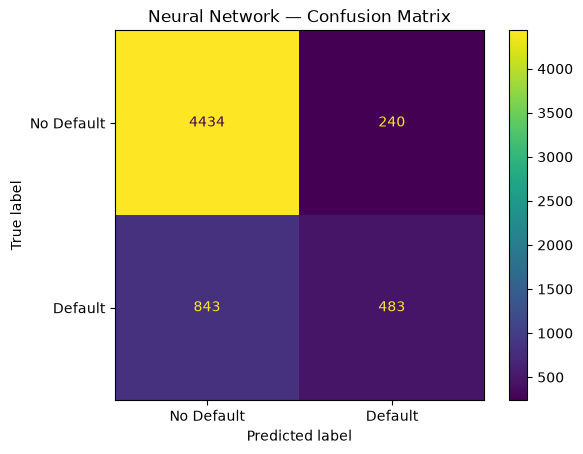

In [54]:
# Confusion Matrix
# In particular, FN are really interesting: The model consider safe a client and that client ends up in DEFAULT
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nn,
    display_labels=["No Default", "Default"]
)

plt.title("Neural Network — Confusion Matrix")
plt.show()

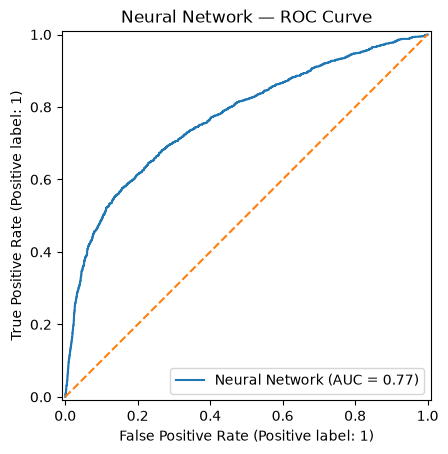

In [55]:
# ROC Curve
# If you randomly pick one applicant who actually defaulted and one applicant who did not, ROC-AUC is the probability that the model assigns a higher default probability to the actual defaulter.
# AUC = 0.50: The model has no discriminatory power (equivalent to a coin flip).
# AUC = 0.75: There is a 75% chance the model scores a defaulter higher than a non-defaulter.
# AUC = 1.00: Perfect separation. Every single defaulter is scored higher than every non-defaulter.
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_nn,
    name="Neural Network"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Neural Network — ROC Curve")
plt.show()

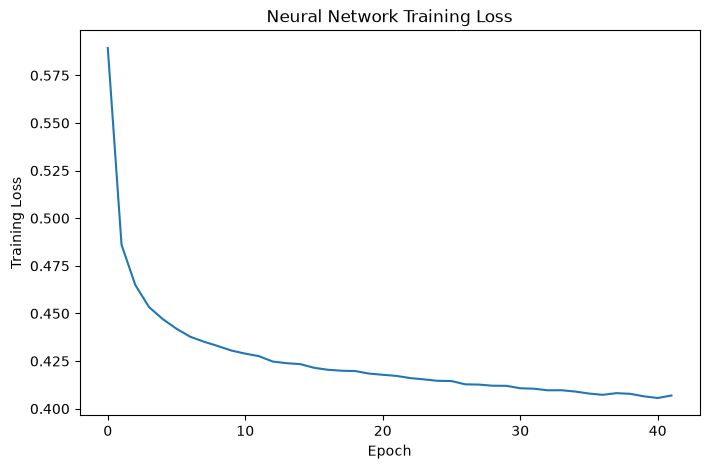

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(nn_model.loss_curve_)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Neural Network Training Loss")

plt.show()

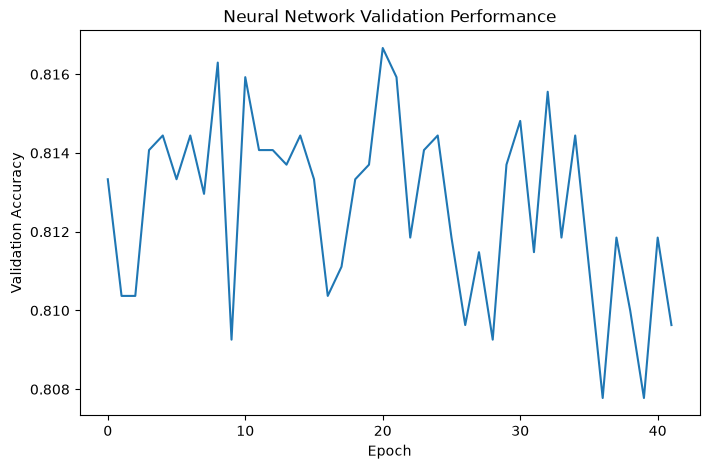

In [57]:
plt.figure(figsize=(8, 5))

plt.plot(nn_model.validation_scores_)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Neural Network Validation Performance")

plt.show()

In [58]:
# ==============================================================================
# PREPARATION FOR EXPLAINERS
# ==============================================================================

def nn_predict_proba_raw(X_input):
    # SHAP/LIME may pass a NumPy array instead of a DataFrame
    if not isinstance(X_input, pd.DataFrame):
        X_input = pd.DataFrame(
            X_input,
            columns=X_train.columns
        )

    X_processed = preprocessor.transform(X_input)

    return nn_model.predict_proba(X_processed)

In [59]:
# Two probabilities per client: P(no default),  P(default)
nn_predict_proba_raw(X_test.head())

array([[0.93431394, 0.06568606],
       [0.74700133, 0.25299867],
       [0.64763265, 0.35236735],
       [0.85253277, 0.14746723],
       [0.94722293, 0.05277707]])

# Level 1 — Explaining the network as a black box

SHAP, LIME and DiCE below only ever call the model through `nn_predict_proba_raw` (raw features in, probabilities out). That means:

* the network is explained in the **original 21 features**, so `EDUCATION` shows up as one feature instead of one column per code;
* the code is identical to what the XGBoost notebook would run, so the two models' explanations are directly comparable.

Install once in the venv: `pip install shap lime dice-ml`

In [60]:
import shap
import dice_ml
from lime.lime_tabular import LimeTabularExplainer

## The applicant we explain

The README calls for **one** high-risk test applicant explained by every method and every model. The group's XGBoost slides explain **applicant #15110** (limit NT$60,000, 2 months late on the latest bill, balance NT$4,114). We use the same person if they're in our test set and the network also declines them. Otherwise we fall back to a real defaulter the network scores near 70%, so the counterfactual has a realistic distance to travel.

In [61]:
proba_test = pd.Series(y_proba_nn, index=X_test.index)

SHARED_APPLICANT = 15110   # the applicant on the group's XGBoost slides
shared_ok = (
    SHARED_APPLICANT in X_test.index
    and X_test.loc[SHARED_APPLICANT, "LIMIT_BAL"] == 60000
    and X_test.loc[SHARED_APPLICANT, "PAY_0"] == 2
    and X_test.loc[SHARED_APPLICANT, "BILL_AMT1"] == 4114
    and proba_test[SHARED_APPLICANT] >= 0.5
)

if shared_ok:
    APPLICANT = SHARED_APPLICANT
else:
    print(f"Applicant {SHARED_APPLICANT} can't be used here (not in this test split, a different row, "
          "or approved by the network). Using a defaulter the network scores near 70% instead.")
    defaulters = proba_test[y_test == 1]
    APPLICANT = (defaulters - 0.70).abs().idxmin()

x_applicant = X_test.loc[[APPLICANT]]   # double brackets keep it a 1-row DataFrame

print(f"Applicant {APPLICANT} | P(default) = {proba_test[APPLICANT]:.3f} | "
      f"actually defaulted: {y_test[APPLICANT]}")
x_applicant

Applicant 15110 | P(default) = 0.685 | actually defaulted: 1


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
15110,60000,2,28,2,0,0,0,0,0,4114.0,5875.0,7612.0,8826.0,10113.0,11289.0,2000.0,2000.0,1500.0,1600.0,1500.0,1500.0


## 1. Kernel SHAP

KernelSHAP is model-agnostic: it only calls the prediction function, so it works on the MLP exactly as on any black box (slowly).

* **Background data** is the reference population every explanation is measured against. We use real rows (`shap.sample`), **not** `shap.kmeans`: k-means centroids average the category codes (e.g. `SEX = 1.4`), which the `OneHotEncoder` treats as unknown and silently encodes as all zeros.
* **`link="logit"`** puts SHAP values in log-odds, the same units TreeSHAP reports for XGBoost by default, so the two models' plots can be compared directly.

In [62]:
background = shap.sample(X_train, 100, random_state=RANDOM_STATE)

def nn_proba_default(X_input):
    return nn_predict_proba_raw(X_input)[:, 1]   # P(default) only

kernel_explainer = shap.KernelExplainer(nn_proba_default, background, link="logit")

100%|██████████| 1/1 [00:00<00:00,  5.70it/s]


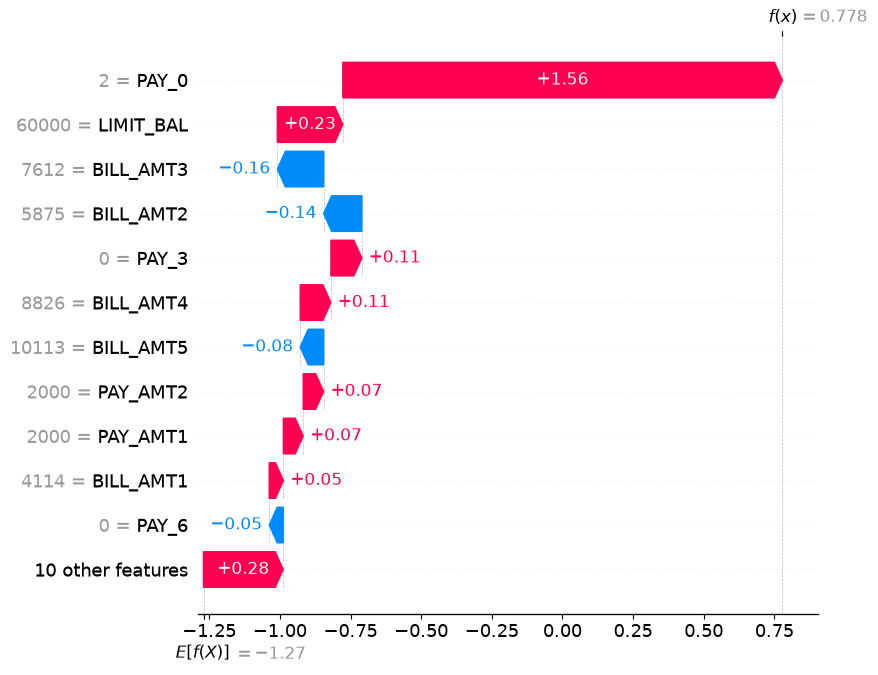

In [63]:
# Local explanation: why does the network score THIS applicant as high risk?
# l1_reg=False keeps all 21 features (the default can zero out small ones to save samples)
np.random.seed(RANDOM_STATE)   # Kernel SHAP samples coalitions with NumPy's global RNG
sv_applicant = kernel_explainer.shap_values(x_applicant, nsamples=2000, l1_reg=False)

applicant_explanation = shap.Explanation(
    values=sv_applicant[0],
    base_values=kernel_explainer.expected_value,
    data=x_applicant.iloc[0].values,
    feature_names=X_train.columns.tolist(),
)

shap.plots.waterfall(applicant_explanation, max_display=12)

### Stress test: Kernel SHAP is an estimate

TreeSHAP is exact, so the group's slide reports 4.0 of 4 reasons matching across re-runs. Kernel SHAP samples feature coalitions instead, so we re-run it with 5 seeds and count how many of the top-4 reasons match the first run.

In [64]:
TOP_K = 4   # adverse-action notices list up to four reasons, as on the group's stability slide

shap_runs = []
for seed in range(5):
    np.random.seed(seed)
    sv = kernel_explainer.shap_values(x_applicant, nsamples=2000, l1_reg=False)[0]
    shap_runs.append(pd.Series(sv, index=X_train.columns))
shap_runs = pd.DataFrame(shap_runs)   # one row per seed

shap_top = [set(r.abs().nlargest(TOP_K).index) for _, r in shap_runs.iterrows()]
print(f"Top-{TOP_K} reasons shared with run 0:", [len(shap_top[0] & s) for s in shap_top])
print("Largest change in any feature's value across runs:",
      round((shap_runs.max() - shap_runs.min()).max(), 3))
shap_runs.T.loc[shap_runs.abs().mean().nlargest(10).index].round(3)

100%|██████████| 1/1 [00:00<00:00,  5.09it/s]

Top-4 reasons shared with run 0: [4, 4, 4, 4, 4]
Largest change in any feature's value across runs: 0.012


,0,1,2,3,4
PAY_0,1.550,1.554,1.555,1.558,1.555
LIMIT_BAL,0.238,0.236,0.236,0.234,0.241
BILL_AMT3,-0.167,-0.169,-0.158,-0.163,-0.164
BILL_AMT2,-0.141,-0.142,-0.138,-0.141,-0.143
PAY_3,0.113,0.118,0.111,0.113,0.115
BILL_AMT4,0.107,0.112,0.107,0.112,0.113
BILL_AMT5,-0.088,-0.089,-0.093,-0.090,-0.091
PAY_AMT2,0.072,0.070,0.071,0.072,0.073
PAY_AMT1,0.072,0.068,0.077,0.070,0.067
BILL_AMT1,0.058,0.059,0.053,0.055,0.052


100%|██████████| 200/200 [00:09<00:00, 21.00it/s]
C:\Users\hashi\AppData\Local\Temp\ipykernel_25100\1798751844.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_global, X_explain, max_display=15)


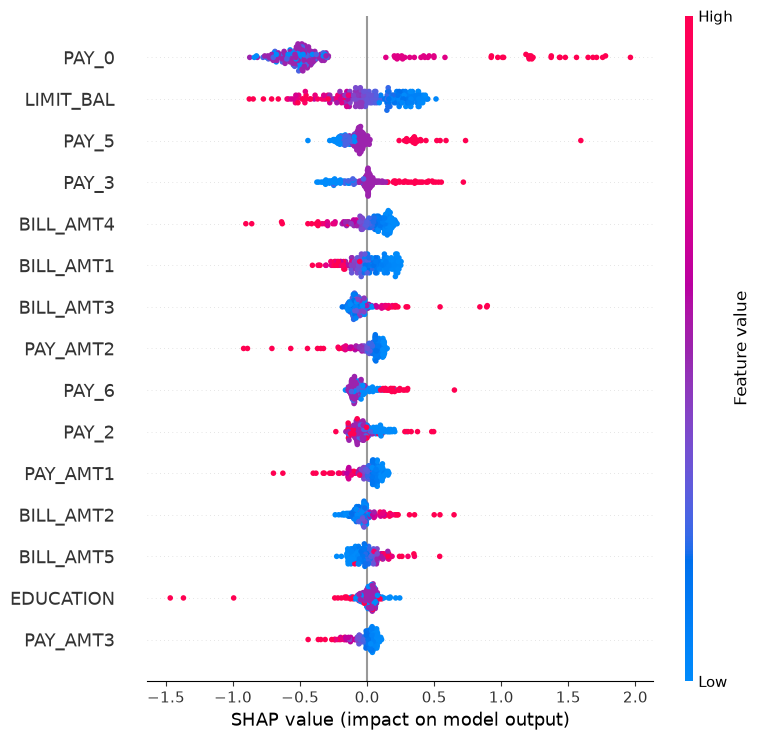

In [65]:
# Global explanation: which features drive the network across many applicants?
# 200 rows x 500 samples x 100 background rows ~ 10M network predictions: expect a few minutes.
# Same random_state as the XGBoost notebook -> same 200 applicants -> comparable plots.
X_explain = X_test.sample(200, random_state=RANDOM_STATE)
np.random.seed(RANDOM_STATE)

sv_global = kernel_explainer.shap_values(X_explain, nsamples=500, l1_reg=False)

shap.summary_plot(sv_global, X_explain, max_display=15)

In [66]:
# Mean |SHAP| ranking, to put side by side with XGBoost's
nn_shap_importance = (
    pd.Series(np.abs(sv_global).mean(axis=0), index=X_train.columns)
    .sort_values(ascending=False)
)
nn_shap_importance.head(10)

PAY_0        0.601663
LIMIT_BAL    0.239477
PAY_5        0.145948
PAY_3        0.131548
BILL_AMT4    0.131320
BILL_AMT1    0.122519
BILL_AMT3    0.099467
PAY_AMT2     0.095661
PAY_6        0.094729
PAY_2        0.083143
dtype: float64

## 2. LIME

LIME samples synthetic applicants around ours, asks the network to score them, and fits a weighted linear model to those scores. The categorical columns are flagged so LIME samples real category codes instead of values like `EDUCATION = 2.6`.

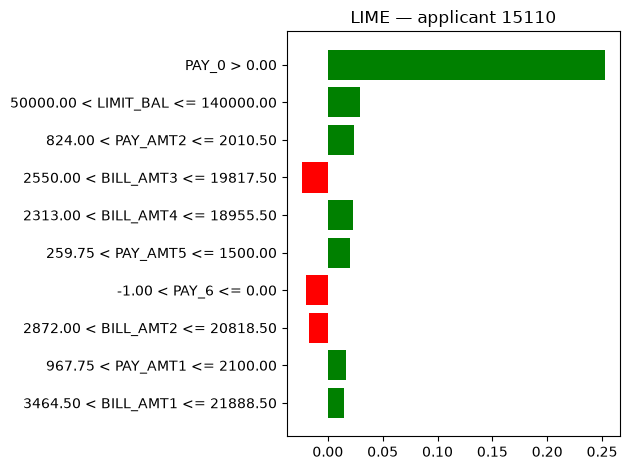

In [67]:
categorical_idx = [X_train.columns.get_loc(c) for c in categorical_features]

def make_lime_explainer(seed):
    return LimeTabularExplainer(
        training_data=X_train.values,
        feature_names=X_train.columns.tolist(),
        class_names=["No default", "Default"],
        categorical_features=categorical_idx,
        mode="classification",
        random_state=seed,
    )

lime_exp = make_lime_explainer(RANDOM_STATE).explain_instance(
    x_applicant.values[0],
    nn_predict_proba_raw,   # LIME wants both class probabilities, which this returns
    num_features=10,
    num_samples=5000,
)

lime_exp.as_pyplot_figure()
plt.title(f"LIME — applicant {APPLICANT}")
plt.tight_layout()
plt.show()

### Stress test: stability

Same applicant, same network, same predicted probability: only LIME's random seed changes. If the explanation moves, that movement comes from LIME, not from the model. As on the group's slide, we compare the **top 4** reasons.

In [68]:
N_RUNS = 20
lime_runs = []

for seed in range(N_RUNS):
    exp = make_lime_explainer(seed).explain_instance(
        x_applicant.values[0], nn_predict_proba_raw, num_features=10, num_samples=5000
    )
    weights = dict(exp.as_map()[1])   # {feature index: weight} for the "Default" class
    lime_runs.append({X_train.columns[i]: w for i, w in weights.items()})

lime_runs = pd.DataFrame(lime_runs)   # one row per seed; NaN = not in that run's top 10

in_top = lime_runs.abs().rank(axis=1, ascending=False) <= TOP_K
lime_stability = pd.DataFrame({
    f"in_top{TOP_K}_%": in_top.mean() * 100,
    "in_top10_%": lime_runs.notna().mean() * 100,
    "mean_weight": lime_runs.mean(),
    "std_weight": lime_runs.std(),
}).sort_values(f"in_top{TOP_K}_%", ascending=False)

# "Of 4 reasons, how many match?" between two LIME re-runs, averaged over every pair of runs
top_sets = [set(in_top.columns[row]) for row in in_top.values]
pairs = [(a, b) for i, a in enumerate(top_sets) for b in top_sets[i + 1:]]
print(f"LIME re-run agreement: {np.mean([len(a & b) for a, b in pairs]):.2f} of {TOP_K} reasons")

lime_stability.round(3)

LIME re-run agreement: 2.61 of 4 reasons


,in_top4_%,in_top10_%,mean_weight,std_weight
PAY_0,100.0,100.0,0.249,0.008
LIMIT_BAL,85.0,100.0,0.028,0.005
PAY_AMT2,70.0,100.0,0.023,0.005
BILL_AMT4,60.0,100.0,0.023,0.005
BILL_AMT2,20.0,75.0,-0.019,0.005
PAY_AMT3,15.0,90.0,0.020,0.003
PAY_2,15.0,70.0,-0.018,0.004
PAY_AMT1,10.0,65.0,0.018,0.004
PAY_4,5.0,25.0,-0.017,0.002
PAY_AMT5,5.0,55.0,0.019,0.002


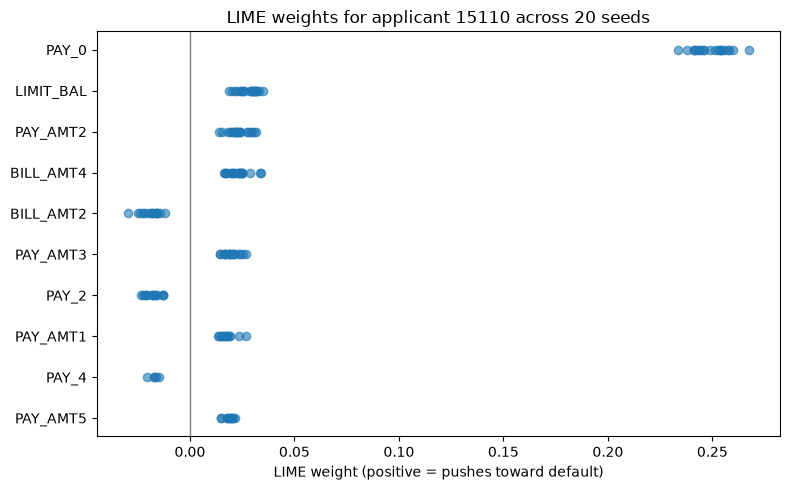

In [69]:
order = lime_stability.index[:10][::-1]

fig, ax = plt.subplots(figsize=(8, 5))
for row, feat in enumerate(order):
    w = lime_runs[feat].dropna()
    ax.scatter(w, [row] * len(w), alpha=0.6, color="C0")
ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("LIME weight (positive = pushes toward default)")
ax.set_title(f"LIME weights for applicant {APPLICANT} across {N_RUNS} seeds")
plt.tight_layout()
plt.show()

### SHAP vs LIME for the same applicant

The two methods are on different scales (SHAP in log-odds, LIME in probability units on discretized features), so we compare **ranks**, not magnitudes.

In [70]:
shap_vs_lime = pd.DataFrame({
    "SHAP (log-odds)": pd.Series(sv_applicant[0], index=X_train.columns),
    f"LIME (mean of {N_RUNS} runs)": lime_runs.mean(),
})
shap_vs_lime["SHAP rank"] = shap_vs_lime.iloc[:, 0].abs().rank(ascending=False)
shap_vs_lime["LIME rank"] = shap_vs_lime.iloc[:, 1].abs().rank(ascending=False)

shap_topk = set(shap_vs_lime["SHAP rank"].nsmallest(TOP_K).index)
lime_topk = set(shap_vs_lime["LIME rank"].nsmallest(TOP_K).index)
print(f"Top-{TOP_K} overlap: {len(shap_topk & lime_topk)}/{TOP_K} -> {sorted(shap_topk & lime_topk)}")

shap_vs_lime.sort_values("SHAP rank").head(10).round(3)

Top-4 overlap: 2/4 -> ['LIMIT_BAL', 'PAY_0']


,SHAP (log-odds),LIME (mean of 20 runs),SHAP rank,LIME rank
PAY_0,1.556,0.249,1.0,1.0
LIMIT_BAL,0.232,0.028,2.0,2.0
BILL_AMT3,-0.164,-0.019,3.0,7.0
BILL_AMT2,-0.135,-0.019,4.0,6.0
PAY_3,0.110,NaN,5.0,NaN
BILL_AMT4,0.109,0.023,6.0,4.0
BILL_AMT5,-0.083,-0.016,7.0,14.0
PAY_AMT2,0.072,0.023,8.0,3.0
PAY_AMT1,0.070,0.018,9.0,10.0
BILL_AMT1,0.050,0.017,10.0,12.0


## 3. Counterfactuals (DiCE)

*What would need to be different for the network to approve this applicant?*

Two data-type traps sit between DiCE and our pipeline:

* DiCE stores categorical values as strings (`"1"`, `"2"`) and writes them back into the applicant's row. Pandas refuses to put `"2"` into an integer column (`TypeError: Invalid value '2' for dtype 'int64'`), which is what broke the unconstrained run. So we hand DiCE the categorical columns **as strings** from the start.
* Our `OneHotEncoder` was fitted on integers, so it would treat `"2"` as an unknown category and **silently encode it as all zeros**, giving wrong predictions with no error. `NNForDiCE` converts the strings back to integers before calling the same preprocessing and network.

In [71]:
# Show every column in the counterfactual tables (pandas hides the middle ones by default,
# which hid BILL_AMT1, one of the features DiCE is allowed to change)
pd.set_option("display.max_columns", None)


class NNForDiCE:
    def predict_proba(self, X_input):
        X_input = pd.DataFrame(X_input, columns=X_train.columns).copy()
        X_input[categorical_features] = (
            X_input[categorical_features].astype(str).astype(float).astype(int)
        )
        return nn_predict_proba_raw(X_input)

    def predict(self, X_input):
        return (self.predict_proba(X_input)[:, 1] >= 0.5).astype(int)


# DiCE works with categorical values as strings, so give it strings from the start
cat_as_str = {c: str for c in categorical_features}
X_train_dice = X_train.astype(cat_as_str)
x_applicant_dice = x_applicant.astype(cat_as_str)

dice_data = dice_ml.Data(
    dataframe=X_train_dice.assign(DEFAULT=y_train),
    continuous_features=numeric_features,
    outcome_name="DEFAULT",
)
dice_model = dice_ml.Model(model=NNForDiCE(), backend="sklearn")
dice_explainer = dice_ml.Dice(dice_data, dice_model, method="random")


def cf_probabilities(cf):
    """The network's P(default) for each counterfactual DiCE returned."""
    ex = cf.cf_examples_list[0]
    # score the rows DiCE displays (its sparser post-processed version when there is one)
    shown = ex.final_cfs_df_sparse if ex.final_cfs_df_sparse is not None else ex.final_cfs_df
    rows = shown[X_train.columns]
    return pd.Series(NNForDiCE().predict_proba(rows)[:, 1], name="P(default)").round(3)

In [72]:
# Step 1: unconstrained. DiCE may change anything, including age or education.
cf_free = dice_explainer.generate_counterfactuals(
    x_applicant_dice,
    total_CFs=5,
    desired_class="opposite",
    random_seed=RANDOM_STATE,
)
cf_free.visualize_as_dataframe(show_only_changes=True)
print(cf_probabilities(cf_free))

100%|██████████| 1/1 [00:00<00:00,  4.30it/s]

Query instance (original outcome : 1)


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,60000,2,28,2,0,0,0,0,0,4114.0,5875.0,7612.0,8826.0,10113.0,11289.0,2000.0,2000.0,1500.0,1600.0,1500.0,1500.0,1



Diverse Counterfactual set (new outcome: 0)


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,-,-,-,-,-,-,-,-,4,-,-,-,-,-,-,-,-,-,-,-,198045.0,0
1,-,-,-,-,-,-,-,-,-,-,-,-,795321.9,-,-,-,-,-,-,-,-,0
2,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,0
3,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,185356.0,-,-,-,-,0
4,-,-,-,-,8,-,-,-,-,-,-,-,-,-,-,-,-,-,479430.5,-,-,0


0    0.449
1    0.025
2    0.300
3    0.385
4    0.032
Name: P(default), dtype: float64


### Stress test: feasibility

Constrained version, using the group's counterfactual rules: only the **latest lateness** (`PAY_0`), the **latest balance** (`BILL_AMT1`) and the **last two payments** (`PAY_AMT1`, `PAY_AMT2`) can change, each in its allowed direction:

* lateness and the balance can only go **down** (paying the balance off in full is the floor);
* payments can only go **up**, capped at the 99th percentile so DiCE doesn't propose absurd amounts.

Everything else is frozen: age and education, earlier months, and the credit limit (the lender's decision). DiCE's random search stands in for the group's own cost-weighted search, so individual counterfactuals won't match theirs one for one.

If DiCE finds no counterfactuals here, that is itself a result: the network gives this applicant no actionable path to approval.

In [73]:
actionable = ["PAY_0", "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]

x0 = x_applicant.iloc[0]


def payment_cap(col):
    return int(max(x0[col], X_train[col].quantile(0.99)))


permitted_range = {
    "PAY_0": [int(X_train["PAY_0"].min()), int(x0["PAY_0"])],              # less late only
    "BILL_AMT1": [min(0, int(x0["BILL_AMT1"])), max(0, int(x0["BILL_AMT1"]))],  # balance down only
    "PAY_AMT1": [int(x0["PAY_AMT1"]), payment_cap("PAY_AMT1")],              # pay more only
    "PAY_AMT2": [int(x0["PAY_AMT2"]), payment_cap("PAY_AMT2")],
}

cf_actionable = dice_explainer.generate_counterfactuals(
    x_applicant_dice,
    total_CFs=5,
    desired_class="opposite",
    features_to_vary=actionable,
    permitted_range=permitted_range,
    random_seed=RANDOM_STATE,
)
cf_actionable.visualize_as_dataframe(show_only_changes=True)
print(cf_probabilities(cf_actionable))

100%|██████████| 1/1 [01:11<00:00, 71.82s/it]

Query instance (original outcome : 1)


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,60000,2,28,2,0,0,0,0,0,4114.0,5875.0,7612.0,8826.0,10113.0,11289.0,2000.0,2000.0,1500.0,1600.0,1500.0,1500.0,1



Diverse Counterfactual set (new outcome: 0)


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,55225.3,-,-,-,-,-,0
1,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,40877.0,-,-,-,-,-,0
2,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,49806.5,52984.2,-,-,-,-,0
3,-,-,-,-1,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,0
4,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,46741.0,-,-,-,-,0


0    0.246
1    0.320
2    0.176
3    0.212
4    0.450
Name: P(default), dtype: float64


### The XGBoost slide's counterfactuals, scored by the network

The group's counterfactual slide gives applicant #15110 two pieces of advice under XGBoost: catch up one month (22%) and pay the balance off in full (49.5%). Here are the same two changes scored by the network.

In [ ]:
assert APPLICANT == 15110, "these are the XGBoost slide's counterfactuals for applicant #15110"

advice = {
    "Catch up one month (PAY_0 2 -> 1)": {"PAY_0": 1},
    "Pay the balance off in full (BILL_AMT1 -> 0)": {"BILL_AMT1": 0},
}
xgboost_slide = {"Catch up one month (PAY_0 2 -> 1)": 0.22, "Pay the balance off in full (BILL_AMT1 -> 0)": 0.495}

rows = {}
for label, changes in advice.items():
    changed = x_applicant.copy()
    for col, value in changes.items():
        changed[col] = value
    p = nn_predict_proba_raw(changed)[0, 1]
    rows[label] = {"XGBoost (slide)": xgboost_slide[label], "Network": round(p, 3),
                   "Network decision": "approved" if p < 0.5 else "declined"}
pd.DataFrame(rows).T